# 01B · Caracterización para el dimensionamiento

Este cuaderno **no optimiza**. Su trabajo es mirar las series horarias y
responder, con física y no con economía, a una pregunta previa:

> ¿Qué rangos de **potencia [MW]** y de **energía [MWh]** del BESS tienen
> utilidad técnica, y cuáles debería poder explorar el cuaderno 02?

La malla que usan hoy los barridos —PV [20, 50, 100, 200] MWp × BESS
[0, 40, 80, 160, 320] MWh a 4 h fijas— se fijó por criterio, no por datos. El
`INFORME` §7.1 documenta la consecuencia: no podía localizar su propio óptimo.

Aquí se construye la evidencia física. **No se modifica ningún cuaderno ni
módulo existente.**

---

## Qué se calcula, y en qué orden

1. **Balance PV–demanda** hora a hora: residual y excedente.
2. **Potencia**, por los dos lados. Descargar contra la demanda y cargar con el
   excedente solar son requisitos muy distintos, y el PCS tiene una sola
   potencia nominal para ambos.
3. **El ciclo de almacenamiento**, definido de amanecer a amanecer para que la
   energía nunca atienda demanda anterior a su propia generación.
4. **Energía desplazable** dentro de cada ciclo.
5. **Curva de captura**: qué fracción de esa energía alcanza cada nivel de
   potencia, y dónde está la rodilla de rendimientos decrecientes.
6. **Del lado AC al BESS nominal**: los tres conceptos de energía y cómo se
   traducen con RTE y DoD.
7. **Comparación entre cuatro tamaños de PV**, porque el cuaderno 02 decide PV y
   BESS conjuntamente.
8. **Dominio físico** y **malla económica propuesta**, que son cosas distintas.

## 1. Datos de entrada

Se reutiliza el entorno del modelo base sin duplicar nada.
`sensibilidad.cargar_entorno_notebook()` ejecuta las celdas 2, 4, 6, 8, 12, 13 y
16 del cuaderno 01 y devuelve el caso ya armado y validado.

| Serie | Procedencia real |
|---|---|
| Demanda | `load variable.csv`, columna `Porvenir` → `leer_demanda_variable` → `demanda.limpiar()`, que imputa los 71 cortes de medidor |
| Generación PV | `Oriental_tmy-2025.csv` → `solar_tmy.perfil_pv("Oriente", 100.0)`, simulada con pvlib |
| Marcas de tiempo | Las genera `solar_tmy`; `preparar_caso` las usa como clave de unión |

El caso base es **Oriente, 100 MWp, año 2025, 8.760 horas**. Para los otros
tamaños de PV se usa `sensibilidad.escalar_pv()`, la misma función que emplean
los barridos existentes.

In [1]:
import logging
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
for _ruidoso in ("pypsa", "linopy"):
    logging.getLogger(_ruidoso).setLevel(logging.ERROR)

import sensibilidad as S
import solar_tmy as ST

FIGURAS = Path("figuras_caracterizacion")
FIGURAS.mkdir(exist_ok=True)

# Paleta del proyecto, validada para daltonismo (ver CLAUDE.md).
AZUL, NARANJA, AQUA, VINO, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#a03060", "#8b8a83"
TINTA = "#2b2a27"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linewidth": 0.6,
    "font.size": 10,
})

g = S.cargar_entorno_notebook()
base = g["df_base"].copy()
dt = g["dt"]

PV_PRINCIPAL = 100.0
PV_ANALISIS = [30.0, 50.0, 70.0, 100.0]

# Supuestos del BESS, tomados del entorno: no se redefinen aquí.
DoD, RTE = g["DoD"], g["eff_rt"]
EFF_C = EFF_D = np.sqrt(RTE)

print(f"Sitio            : {g['sitio']}")
print(f"Año simulado     : {g['anio_simulacion']}")
print(f"Horas del caso   : {len(base):,}")
print(f"PV principal     : {PV_PRINCIPAL:.0f} MWp")
print(f"PV a comparar    : {[f'{p:.0f}' for p in PV_ANALISIS]} MWp")
print()
print(f"DoD              : {DoD:.0%}")
print(f"RTE              : {RTE:.0%}")
print(f"eff_c = eff_d    : {EFF_C:.4f}   (reparto simétrico, como en los modelos)")

Sitio            : Oriente
Año simulado     : 2025
Horas del caso   : 8,760
PV principal     : 100 MWp
PV a comparar    : ['30', '50', '70', '100'] MWp

DoD              : 80%
RTE              : 90%
eff_c = eff_d    : 0.9487   (reparto simétrico, como en los modelos)


### Una aclaración de unidades

`pv_nominal_MW = 100` son **MWp en corriente continua**, no potencia AC. La
potencia AC de la planta es `MWp / DC_AC_RATIO`, y con las pérdidas de sistema el
pico observado queda por debajo. Leer los 100 MWp como pico de inyección llevaría
a sobredimensionar la potencia del BESS.

In [2]:
pv_ac_nominal = PV_PRINCIPAL / ST.DC_AC_RATIO

print(f"PV nominal DC          : {PV_PRINCIPAL:>7.2f} MWp")
print(f"DC/AC                  : {ST.DC_AC_RATIO:>7.2f}")
print(f"PV nominal AC          : {pv_ac_nominal:>7.2f} MWac   <- donde recorta el inversor")
print(f"PV pico observado      : {base['PV_MW'].max():>7.2f} MW")
print(f"Pérdidas de sistema    : {ST.PERDIDAS_SISTEMA_PCT:>7.2f} %")
print()
print(f"Demanda pico           : {base['Load_MW'].max():>7.2f} MW")
print(f"Demanda media          : {base['Load_MW'].mean():>7.2f} MW")
print(f"Razón pico PV / pico demanda : {base['PV_MW'].max() / base['Load_MW'].max():>5.2f}x")

PV nominal DC          :  100.00 MWp
DC/AC                  :    1.20
PV nominal AC          :   83.33 MWac   <- donde recorta el inversor
PV pico observado      :   78.25 MW
Pérdidas de sistema    :   14.08 %

Demanda pico           :   23.23 MW
Demanda media          :   18.12 MW
Razón pico PV / pico demanda :  3.37x


## 2. El ciclo de almacenamiento: de amanecer a amanecer

Antes de calcular ninguna energía hay que fijar **qué ventana temporal** se está
considerando, y aquí es donde una definición cómoda produce un resultado
imposible.

### Por qué el día calendario no sirve

Si se agrupa por día calendario, la «demanda nocturna del día *d*» incluye las
horas de 00:00 a 05:00 — que ocurren **antes** de que salga el sol del día *d*.
Esa energía no puede haber sido cargada con la generación de ese mismo día: la
batería tendría que descargarse antes de haberse cargado.

### La definición que se usa

Un **ciclo** va desde el **primer instante con sol de un día** hasta el primer
instante con sol del día siguiente. Dentro de esa ventana:

- primero llegan las horas solares, donde el BESS **carga** con el excedente;
- después las horas sin sol —tarde, noche y madrugada del día siguiente— donde
  el BESS **descarga** contra el residual.

Así toda descarga es posterior a su carga, por construcción. La madrugada queda
asignada al ciclo que empezó el día anterior, que es de donde físicamente puede
venir su energía.

Los ciclos incompletos de los extremos del año —antes del primer amanecer y
después del último— se descartan.

In [3]:
def marcar_ciclos(d, pv_ac_nom):
    """Añade `Es_solar` y `Ciclo`, con el ciclo de amanecer a amanecer.

    El amanecer es la primera hora con sol de cada día calendario. Definirlo así
    —en vez de por transición no-solar → solar— evita que una hora nublada de
    mediodía parta el ciclo en dos.
    """
    d = d.copy()
    d["Es_solar"] = d["PV_MW"] >= 0.01 * pv_ac_nom

    amaneceres = (
        d.loc[d["Es_solar"]]
        .groupby(d["Fecha"].dt.floor("D"))["Fecha"]
        .min()
        .to_numpy()
    )
    d["Ciclo"] = np.searchsorted(amaneceres, d["Fecha"].to_numpy(), side="right") - 1

    # Ciclo -1: horas anteriores al primer amanecer del año. El último ciclo no
    # llega a cerrar. Los dos son incompletos y se descartan.
    completos = d["Ciclo"].between(0, d["Ciclo"].max() - 1)
    return d, completos


df, completos = marcar_ciclos(S.escalar_pv(base, PV_PRINCIPAL), pv_ac_nominal)
df["Residual_MW"] = (df["Load_MW"] - df["PV_MW"]).clip(lower=0)
df["Excedente_PV_MW"] = (df["PV_MW"] - df["Load_MW"]).clip(lower=0)

# Guardas del balance.
assert (df["Residual_MW"] >= 0).all() and (df["Excedente_PV_MW"] >= 0).all()
assert ((df["Residual_MW"] > 0) & (df["Excedente_PV_MW"] > 0)).sum() == 0
_cierre = (df["Load_MW"] - df["PV_MW"]) - (df["Residual_MW"] - df["Excedente_PV_MW"])
assert _cierre.abs().max() < 1e-9, "El balance horario no cierra"

# Guarda de causalidad. La propiedad que hay que verificar es que cada ciclo
# empiece en el amanecer: si empieza con sol, toda hora sin sol del ciclo es
# posterior a generación, y ninguna descarga precede a su carga. Comprueba de
# verdad el `searchsorted`, que es donde puede salir mal.
assert df[completos].groupby("Ciclo")["Es_solar"].first().all(), \
    "Hay ciclos que no empiezan en el amanecer"

print(f"Ciclos completos          : {df.loc[completos, 'Ciclo'].nunique():,}")
print(f"Horas descartadas         : {(~completos).sum()}  (extremos del año)")
print(f"Duración media del ciclo  : {completos.sum() / df.loc[completos, 'Ciclo'].nunique():.1f} h")
print()
print("Causalidad verificada: en todo ciclo el sol precede a la noche.")

Ciclos completos          : 364
Horas descartadas         : 24  (extremos del año)
Duración media del ciclo  : 24.0 h

Causalidad verificada: en todo ciclo el sol precede a la noche.


### Cuánto cambia respecto al día calendario

Conviene cuantificar el error de la definición incorrecta, porque es la que sale
de forma natural y aparecía en la primera versión de este cuaderno.

In [4]:
df["DiaCal"] = df["Fecha"].dt.floor("D")


def energia_por_grupo(d, columna_grupo, mascara=None):
    """Excedente, residual sin sol y desplazable, agrupados por la columna dada."""
    dd = d if mascara is None else d[mascara]
    agr = dd.groupby(columna_grupo).apply(
        lambda c: pd.Series({
            "E_exc": (c["Excedente_PV_MW"] * dt).sum(),
            "E_res": (c.loc[~c["Es_solar"], "Residual_MW"] * dt).sum(),
        }),
        include_groups=False,
    )
    agr["E_shift"] = agr[["E_exc", "E_res"]].min(axis=1)
    return agr


cal = energia_por_grupo(df, "DiaCal")
cic = energia_por_grupo(df, "Ciclo", completos)

comp = pd.DataFrame({
    "Día calendario (no causal)": [cal["E_res"].mean(), cal["E_shift"].mean(),
                                   cal["E_shift"].sum()],
    "Ciclo amanecer→amanecer": [cic["E_res"].mean(), cic["E_shift"].mean(),
                                cic["E_shift"].sum()],
}, index=["Residual sin sol, media [MWh]", "Desplazable, media [MWh]",
          "Desplazable, anual [MWh]"])
comp["Diferencia [%]"] = (comp.iloc[:, 1] / comp.iloc[:, 0] - 1) * 100
display(comp.round(2))

print("\nEl día calendario reparte la madrugada al ciclo equivocado. La diferencia")
print("es pequeña porque la demanda es plana, pero la definición causal es la")
print("correcta y es la que se usa de aquí en adelante.")

diario = cic  # a partir de aqui son ciclos causales

,Día calendario (no causal),Ciclo amanecer→amanecer,Diferencia [%]
"Residual sin sol, media [MWh]",227.94,227.89,-0.02
"Desplazable, media [MWh]",178.04,178.37,0.18
"Desplazable, anual [MWh]",64986.18,64926.10,-0.09



El día calendario reparte la madrugada al ciclo equivocado. La diferencia
es pequeña porque la demanda es plana, pero la definición causal es la
correcta y es la que se usa de aquí en adelante.


## 3. Potencia: los dos lados no son simétricos

La reacción natural es dimensionar la potencia por la **descarga** —cuánto hay
que entregar a la carga— y olvidar que el mismo convertidor tiene que
**absorber** el excedente solar de mediodía.

En este sistema los dos requisitos no se parecen: la demanda es pequeña y plana,
mientras que el excedente llega concentrado en picos de mediodía. El PCS tiene
**una sola potencia nominal**, así que manda el lado exigente.

In [5]:
def resumen_estadistico(serie, nombre, unidad):
    """Media, máximo y percentiles de una serie."""
    fila = {"Media": serie.mean(), "Máximo": serie.max()}
    fila.update({f"P{p}": np.percentile(serie, p) for p in (25, 50, 75, 90, 95)})
    return pd.Series(fila, name=f"{nombre} [{unidad}]")


residual_pos = df.loc[df["Residual_MW"] > 0, "Residual_MW"]
excedente_pos = df.loc[df["Excedente_PV_MW"] > 0, "Excedente_PV_MW"]

display(pd.DataFrame([
    resumen_estadistico(residual_pos, "Descargar · residual", "MW"),
    resumen_estadistico(excedente_pos, "Cargar · excedente solar", "MW"),
]).round(2))

print(f"\nEl excedente pico es {excedente_pos.max() / residual_pos.max():.1f}x el residual pico.")

,Media,Máximo,P25,P50,P75,P90,P95
Descargar · residual [MW],16.52,22.63,14.44,18.52,20.15,20.93,21.29
Cargar · excedente solar [MW],27.00,71.07,12.76,26.27,40.61,50.94,54.42



El excedente pico es 3.1x el residual pico.


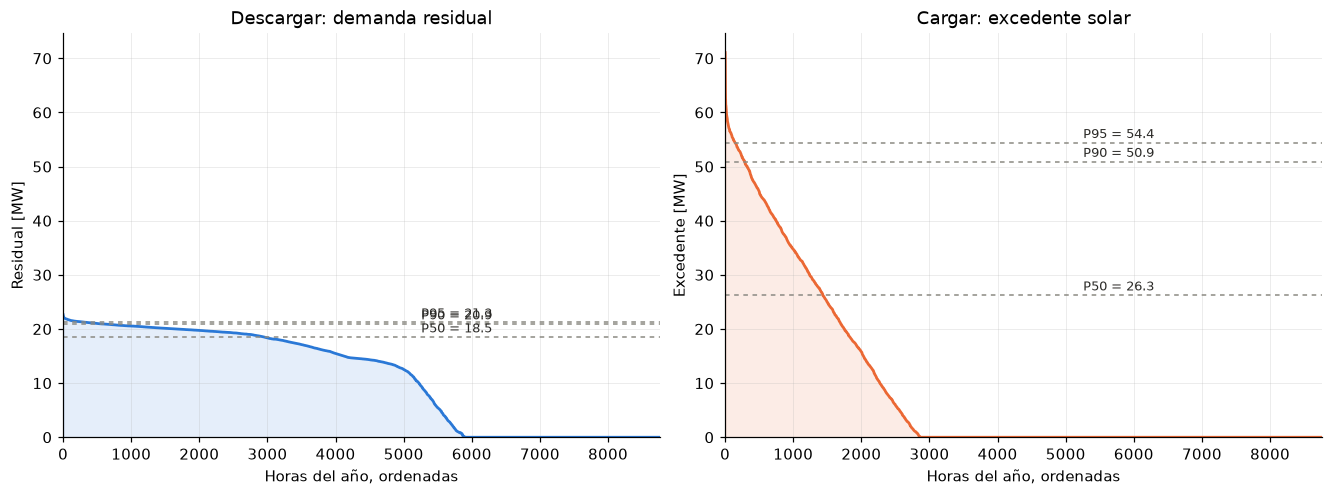

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True)
tope = max(df["Residual_MW"].max(), df["Excedente_PV_MW"].max()) * 1.05

for ax, serie, color, titulo, etiqueta in [
    (ax1, df["Residual_MW"], AZUL, "Descargar: demanda residual", "Residual [MW]"),
    (ax2, df["Excedente_PV_MW"], NARANJA, "Cargar: excedente solar", "Excedente [MW]"),
]:
    orden = np.sort(serie.to_numpy())[::-1]
    horas = np.arange(1, len(orden) + 1)
    ax.plot(horas, orden, color=color, lw=1.8)
    ax.fill_between(horas, orden, color=color, alpha=0.12)
    pos = serie[serie > 0]
    for p in (50, 90, 95):
        v = np.percentile(pos, p)
        ax.axhline(v, color=GRIS, ls=(0, (3, 3)), lw=1)
        ax.annotate(f"P{p} = {v:.1f}", xy=(len(orden) * 0.6, v), xytext=(0, 3),
                    textcoords="offset points", fontsize=8.5, color=TINTA)
    ax.set(xlabel="Horas del año, ordenadas", ylabel=etiqueta, title=titulo,
           xlim=(0, len(orden)), ylim=(0, tope))

fig.savefig(FIGURAS / "01_curvas_duracion_potencia.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Energía desplazable dentro del ciclo

Sin suponer ninguna estrategia de arbitraje. Para cada ciclo:

- `E_exc` — excedente solar acumulado en las horas con sol.
- `E_res` — residual acumulado en las horas sin sol **posteriores**.
- `E_shift = min(E_exc, E_res)` — la cota de lo desplazable.

El mínimo es la cota: no se puede mover más energía de la que sobra, ni más de la
que hace falta. Sigue siendo una **cota superior**, porque todavía ignora
potencia, RTE y DoD. Esas restricciones entran en las secciones 5 y 6.

In [7]:
display(pd.DataFrame([
    resumen_estadistico(diario["E_exc"], "Excedente solar por ciclo", "MWh"),
    resumen_estadistico(diario["E_res"], "Residual sin sol por ciclo", "MWh"),
    resumen_estadistico(diario["E_shift"], "Desplazable por ciclo", "MWh"),
]).round(1))

limita = np.where(diario["E_exc"] < diario["E_res"], "excedente solar", "demanda nocturna")
print(f"\nCiclos analizados: {len(diario):,}")
print("\n¿Qué limita el desplazamiento?")
print(pd.Series(limita).value_counts().to_string())

,Media,Máximo,P25,P50,P75,P90,P95
Excedente solar por ciclo [MWh],211.7,487.6,143.9,211.5,286.2,329.6,350.9
Residual sin sol por ciclo [MWh],227.9,320.7,208.8,239.0,251.1,262.3,266.9
Desplazable por ciclo [MWh],178.4,283.5,142.5,183.4,230.7,250.1,257.2



Ciclos analizados: 364

¿Qué limita el desplazamiento?
excedente solar     198
demanda nocturna    166


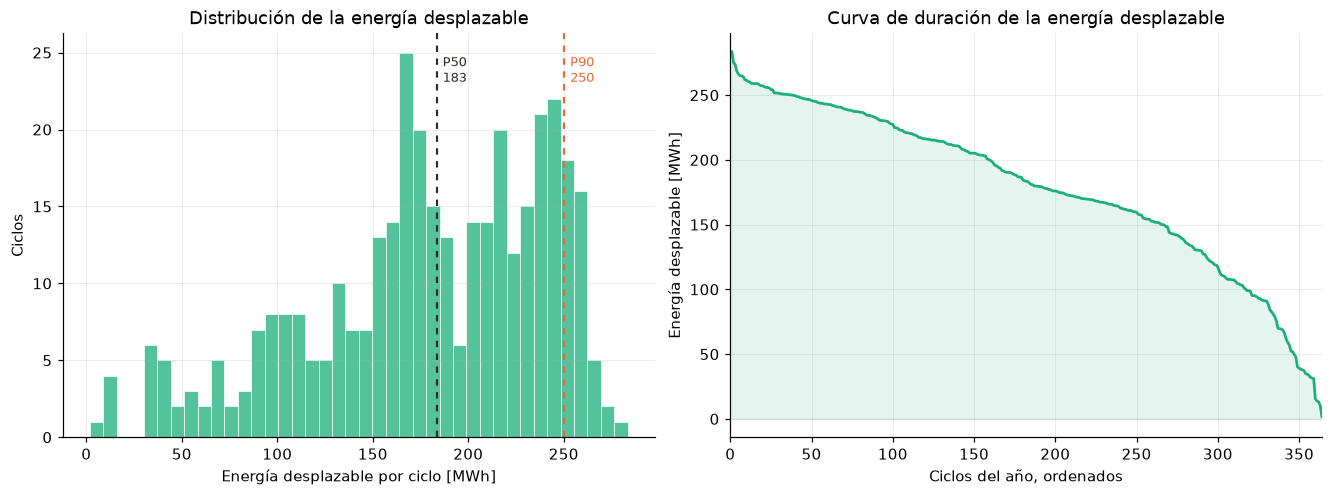

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True)

ax1.hist(diario["E_shift"], bins=40, color=AQUA, alpha=0.75, edgecolor="white", lw=0.6)
for p, col in [(50, TINTA), (90, NARANJA)]:
    v = np.percentile(diario["E_shift"], p)
    ax1.axvline(v, color=col, ls=(0, (3, 3)), lw=1.4)
    ax1.annotate(f"P{p}\n{v:.0f}", xy=(v, ax1.get_ylim()[1] * 0.88), xytext=(4, 0),
                 textcoords="offset points", fontsize=8.5, color=col)
ax1.set(xlabel="Energía desplazable por ciclo [MWh]", ylabel="Ciclos",
        title="Distribución de la energía desplazable")

orden = np.sort(diario["E_shift"].to_numpy())[::-1]
ax2.plot(np.arange(1, len(orden) + 1), orden, color=AQUA, lw=1.8)
ax2.fill_between(np.arange(1, len(orden) + 1), orden, color=AQUA, alpha=0.12)
ax2.set(xlabel="Ciclos del año, ordenados", ylabel="Energía desplazable [MWh]",
        title="Curva de duración de la energía desplazable", xlim=(0, len(orden)))

fig.savefig(FIGURAS / "02_energia_desplazable.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Curva de captura y la rodilla

Un BESS de `P` MW no puede cargar ni descargar más de `P` en ninguna hora.
Recortando las dos series a `P` y volviendo a tomar el mínimo por ciclo se
obtiene cuánta energía es realmente capturable.

**La duración nominal no limita por sí sola.** Un BESS de 60 MW / 240 MWh se
llama «de 4 h» porque a potencia máxima dura 4 h; si la carga pide 20 MW, entrega
20 MW y esos 240 MWh duran 12 horas. La duración de placa es una **razón de
diseño**, no un límite de operación. Lo que limita es la potencia frente al
perfil que hay que seguir.

**Aquí no se fija ningún umbral de captura deseable.** El objetivo es dibujar la
curva completa —del 25 % al 100 %— y localizar la **rodilla**: el punto a partir
del cual cada MW adicional captura mucha menos energía. Si conviene operar antes
o después de esa rodilla es una pregunta económica, no física.

In [9]:
def capturada(d, mascara, ciclo_shift, P_MW):
    """Energía desplazable anual con un límite de potencia de P MW.

    Recorta carga y descarga a P y vuelve a tomar el mínimo por ciclo. Sigue sin
    aplicar RTE ni DoD: es capacidad de conversión, no de almacenamiento.
    """
    dd = d[mascara]
    carga = np.minimum(dd["Excedente_PV_MW"], P_MW) * dt
    desc = np.where(~dd["Es_solar"], np.minimum(dd["Residual_MW"], P_MW), 0.0) * dt
    por = pd.DataFrame({"c": carga, "d": desc, "k": dd["Ciclo"]}).groupby("k").sum()
    return float(np.minimum(np.minimum(por["c"], por["d"]), ciclo_shift).sum())


def curva_captura(d, mascara, ciclo_shift, potencias):
    objetivo = float(ciclo_shift.sum())
    return pd.DataFrame({
        "P [MW]": potencias,
        "Capturado [MWh]": [capturada(d, mascara, ciclo_shift, P) for P in potencias],
    }).assign(**{"% del máximo físico":
                 lambda t: t["Capturado [MWh]"] / objetivo * 100})


def rodilla_de(cur):
    """Rodilla por distancia maxima a la cuerda entre los extremos de la curva.

    Se normalizan los dos ejes a [0, 1] y se busca el punto mas alejado de la
    recta que une el primer punto con el ultimo. Es el criterio habitual y, a
    diferencia de un umbral sobre la pendiente, no depende del espaciado de la
    malla de potencias.
    """
    x = cur["P [MW]"].to_numpy(float)
    y = cur["% del máximo físico"].to_numpy(float)
    xn = (x - x.min()) / np.ptp(x)
    yn = (y - y.min()) / np.ptp(y)
    return float(x[np.argmax(yn - xn)])


potencias = [2, 5, 8, 10, 12, 15, 18, 20, 22, 25, 30, 35, 40, 45, 50, 60, 70, 80]
captura = curva_captura(df, completos, diario["E_shift"], potencias)
objetivo = float(diario["E_shift"].sum())

# Niveles pedidos, incluyendo los pequeños: la rodilla puede estar abajo.
niveles = [25, 50, 75, 90, 95, 98, 100]
tabla_niveles = pd.DataFrame({
    "Captura objetivo [%]": niveles,
    "Potencia necesaria [MW]": [
        np.interp(n, captura["% del máximo físico"], captura["P [MW]"]) for n in niveles
    ],
})
tabla_niveles["MW por punto adicional"] = (
    tabla_niveles["Potencia necesaria [MW]"].diff()
    / tabla_niveles["Captura objetivo [%]"].diff()
)
display(tabla_niveles.round(2).set_index("Captura objetivo [%]"))

print(f"\nMáximo físico sin límite de potencia: {objetivo:,.0f} MWh/año")
print(f"Techo de la descarga hacia la demanda residual: {df['Residual_MW'].max():.1f} MW.")
print()
print("Ese techo acota UN uso concreto —descargar exclusivamente contra la carga—,")
print("no la potencia util del BESS. Por encima siguen teniendo valor la carga")
print("rapida del excedente de mediodia, la carga desde la red en horas baratas y")
print("la descarga o exportacion a la red cuando la estrategia y la tarifa lo")
print("permiten. Cual de esos usos paga es una pregunta del cuaderno 02.")

,Potencia necesaria [MW],MW por punto adicional
Captura objetivo [%],,
25,6.17,NaN
50,13.35,0.29
75,22.22,0.35
90,30.16,0.53
95,34.87,0.94
98,40.23,1.79
100,80.00,19.88



Máximo físico sin límite de potencia: 64,926 MWh/año
Techo de la descarga hacia la demanda residual: 22.6 MW.

Ese techo acota UN uso concreto —descargar exclusivamente contra la carga—,
no la potencia util del BESS. Por encima siguen teniendo valor la carga
rapida del excedente de mediodia, la carga desde la red en horas baratas y
la descarga o exportacion a la red cuando la estrategia y la tarifa lo
permiten. Cual de esos usos paga es una pregunta del cuaderno 02.


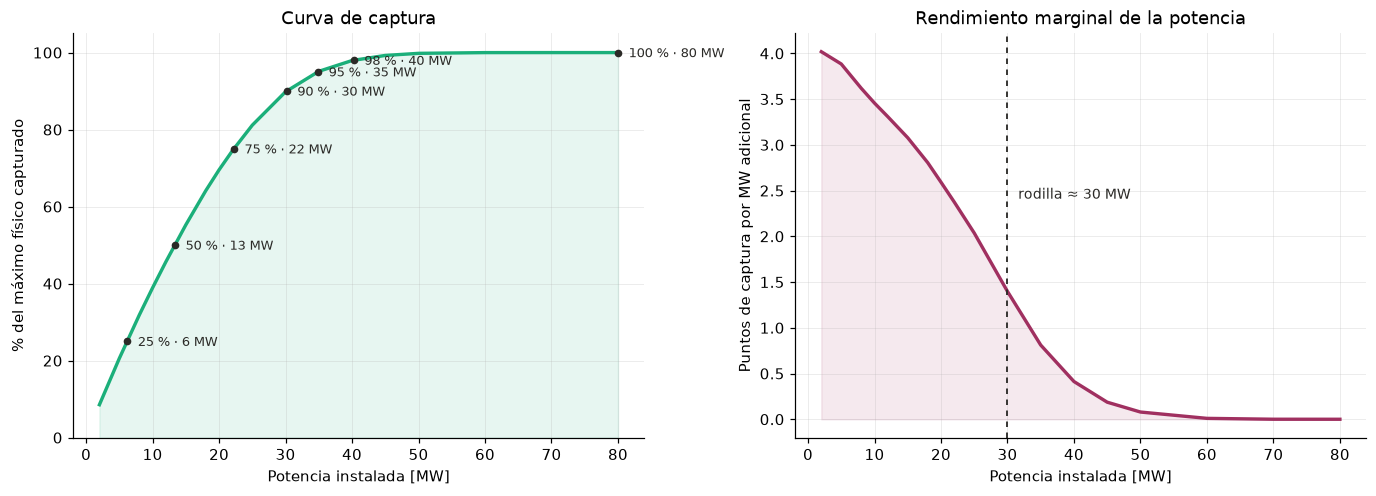

Rodilla estimada: 30 MW  (90 % de captura)


In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.4, 4.4), constrained_layout=True)

ax1.plot(captura["P [MW]"], captura["% del máximo físico"], "-", color=AQUA, lw=2.2)
ax1.fill_between(captura["P [MW]"], captura["% del máximo físico"], color=AQUA, alpha=0.10)
for n in niveles:
    p = np.interp(n, captura["% del máximo físico"], captura["P [MW]"])
    ax1.plot([p], [n], "o", color=TINTA, markersize=4)
    ax1.annotate(f"{n} % · {p:.0f} MW", xy=(p, n), xytext=(7, -3),
                 textcoords="offset points", fontsize=8.2, color=TINTA)
ax1.set(xlabel="Potencia instalada [MW]", ylabel="% del máximo físico capturado",
        title="Curva de captura", ylim=(0, 105))

# El rendimiento marginal hace visible la rodilla.
marg = np.gradient(captura["% del máximo físico"].to_numpy(),
                   captura["P [MW]"].to_numpy())
ax2.plot(captura["P [MW]"], marg, "-", color=VINO, lw=2.2)
ax2.fill_between(captura["P [MW]"], marg, color=VINO, alpha=0.10)
rodilla = rodilla_de(captura)
ax2.axvline(rodilla, color=TINTA, ls=(0, (3, 3)), lw=1.2)
ax2.annotate(f"rodilla ≈ {rodilla:.0f} MW", xy=(rodilla, marg.max() * 0.6),
             xytext=(7, 0), textcoords="offset points", fontsize=9, color=TINTA)
ax2.set(xlabel="Potencia instalada [MW]",
        ylabel="Puntos de captura por MW adicional",
        title="Rendimiento marginal de la potencia")

fig.savefig(FIGURAS / "03_captura_y_rodilla.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"Rodilla estimada: {rodilla:.0f} MW  "
      f"({np.interp(rodilla, captura['P [MW]'], captura['% del máximo físico']):.0f} % de captura)")

## 6. Tres energías distintas, y cómo se traducen

Hasta aquí todo está en el **lado AC**. Confundir eso con la capacidad nominal de
una batería es un error de un factor apreciable. Hay que separar tres cosas:

| # | Concepto | Dónde se mide |
|---|---|---|
| 1 | **Excedente AC disponible** | En el punto de conexión, antes de entrar al BESS |
| 2 | **Energía almacenada** | Dentro de la batería, después de las pérdidas de carga |
| 3 | **Energía entregada a la carga** | En el punto de conexión, después de las pérdidas de descarga |

Con el reparto simétrico que usan los modelos —`eff_c = eff_d = √RTE`— las
relaciones son:

$$E_{almacenada} = E_{AC,entrada}\cdot\eta_c \qquad
E_{entregada} = E_{almacenada}\cdot\eta_d = E_{AC,entrada}\cdot RTE$$

Y la **capacidad nominal** tiene que ser mayor que la energía almacenada, porque
solo se usa una fracción `DoD` de la placa:

$$C_{nominal} = \frac{E_{almacenada}}{DoD}$$

Por eso **no es cierto que un BESS de X MWh nominales capture X MWh de
excedente**. La cadena completa encoge por los dos extremos.

In [11]:
ac_entrada = np.array([np.percentile(diario["E_shift"], p) for p in (25, 50, 75, 90, 95)])
etiquetas = [f"P{p}" for p in (25, 50, 75, 90, 95)]

trad = pd.DataFrame({
    "Nivel": etiquetas,
    "1 · Excedente AC [MWh]": ac_entrada,
    "2 · Almacenado [MWh]": ac_entrada * EFF_C,
    "3 · Entregado a carga [MWh]": ac_entrada * RTE,
    "Capacidad nominal [MWh]": ac_entrada * EFF_C / DoD,
})
trad["Nominal / AC"] = trad["Capacidad nominal [MWh]"] / trad["1 · Excedente AC [MWh]"]
display(trad.round(1).set_index("Nivel"))

print(f"\nPara mover 1 MWh desde el lado AC hacen falta {EFF_C / DoD:.3f} MWh de placa,")
print(f"y solo llegan {RTE:.0%} a la carga.")
print()
print("Dicho de otro modo: una batería de 100 MWh nominales puede absorber como")
print(f"máximo {DoD / EFF_C * 100:.0f} MWh de excedente AC por ciclo y entregar")
print(f"{DoD * EFF_D * 100:.0f} MWh a la carga.")

,1 · Excedente AC [MWh],2 · Almacenado [MWh],3 · Entregado a carga [MWh],Capacidad nominal [MWh],Nominal / AC
Nivel,,,,,
P25,142.5,135.2,128.3,169.0,1.2
P50,183.4,174.0,165.1,217.5,1.2
P75,230.7,218.9,207.7,273.6,1.2
P90,250.1,237.3,225.1,296.6,1.2
P95,257.2,244.0,231.5,305.1,1.2



Para mover 1 MWh desde el lado AC hacen falta 1.186 MWh de placa,
y solo llegan 90% a la carga.

Dicho de otro modo: una batería de 100 MWh nominales puede absorber como
máximo 84 MWh de excedente AC por ciclo y entregar
76 MWh a la carga.


## 7. La caracterización depende del tamaño del PV

El cuaderno 02 decide PV y BESS **conjuntamente**, así que derivar la malla del
BESS solo del caso de 100 MWp sesgaría el resultado. Se repiten las métricas
clave para cuatro tamaños.

Con menos PV hay menos excedente, y por tanto tanto la potencia como la energía
útiles bajan. Cuánto es lo que interesa medir.

> **`PV_ANALISIS = [30, 50, 70, 100]` son puntos de caracterización, no una malla
> de decisión.** Existen para medir cómo se mueve el requisito del BESS con el
> tamaño del PV, y **no deben sustituir el eje de PV del cuaderno 02**, que hoy
> es `[0, 10, 20, 30, 40, 50, 70, 100, 150]`. Ese eje tiene que conservar el
> **PV = 0** (comprar toda la energía de la red), los **tamaños pequeños**, el
> caso de **PV sin batería**, y **tamaños por encima de 100 MWp**. Reducirlo a
> estos cuatro puntos eliminaría casos que el óptimo económico podría ocupar.

In [12]:
def caracterizar(pv_MWp):
    """Métricas físicas de un tamaño de PV. Reutiliza `S.escalar_pv`."""
    d, comp_ = marcar_ciclos(S.escalar_pv(base, pv_MWp), pv_MWp / ST.DC_AC_RATIO)
    d["Residual_MW"] = (d["Load_MW"] - d["PV_MW"]).clip(lower=0)
    d["Excedente_PV_MW"] = (d["PV_MW"] - d["Load_MW"]).clip(lower=0)

    ciclos = energia_por_grupo(d, "Ciclo", comp_)
    pv_anual = float((d["PV_MW"] * dt).sum())
    exc_anual = float((d["Excedente_PV_MW"] * dt).sum())

    cur = curva_captura(d, comp_, ciclos["E_shift"], potencias)
    p_para = {n: float(np.interp(n, cur["% del máximo físico"], cur["P [MW]"]))
              for n in (50, 75, 90, 95, 98)}

    return {
        "PV [MWp]": pv_MWp,
        "PV anual [GWh]": pv_anual / 1000,
        "Excedente anual [GWh]": exc_anual / 1000,
        "Excedente / PV [%]": exc_anual / pv_anual * 100 if pv_anual else np.nan,
        "Residual pico [MW]": float(d["Residual_MW"].max()),
        "P 50 % [MW]": p_para[50],
        "P 75 % [MW]": p_para[75],
        "P 90 % [MW]": p_para[90],
        "P 95 % [MW]": p_para[95],
        "P 98 % [MW]": p_para[98],
        "E desplazable P50 [MWh]": float(np.percentile(ciclos["E_shift"], 50)),
        "E desplazable P75 [MWh]": float(np.percentile(ciclos["E_shift"], 75)),
        "E desplazable P90 [MWh]": float(np.percentile(ciclos["E_shift"], 90)),
        "E desplazable P95 [MWh]": float(np.percentile(ciclos["E_shift"], 95)),
        "E desplazable anual [GWh]": float(ciclos["E_shift"].sum()) / 1000,
        "_ciclos": ciclos,
        "_curva": cur,
    }


resultados = {pv: caracterizar(pv) for pv in PV_ANALISIS}

comparativa = pd.DataFrame(
    [{k: v for k, v in r.items() if not k.startswith("_")} for r in resultados.values()]
).set_index("PV [MWp]")
display(comparativa.round(2))

,PV anual [GWh],Excedente anual [GWh],Excedente / PV [%],Residual pico [MW],P 50 % [MW],P 75 % [MW],P 90 % [MW],P 95 % [MW],P 98 % [MW],E desplazable P50 [MWh],E desplazable P75 [MWh],E desplazable P90 [MWh],E desplazable P95 [MWh],E desplazable anual [GWh]
PV [MWp],,,,,,,,,,,,,,
30.0,41.62,2.33,5.60,22.92,2.00,4.02,6.11,7.64,9.88,2.56,7.90,16.86,23.96,2.11
50.0,69.37,18.16,26.18,22.72,5.72,9.84,13.98,16.24,18.23,43.78,73.39,90.02,99.01,17.70
70.0,97.12,40.35,41.55,22.63,9.72,16.79,23.36,27.14,29.97,106.84,152.06,177.94,191.57,39.27
100.0,138.74,77.36,55.76,22.63,13.35,22.22,30.16,34.87,40.23,183.39,230.72,250.15,257.25,64.93


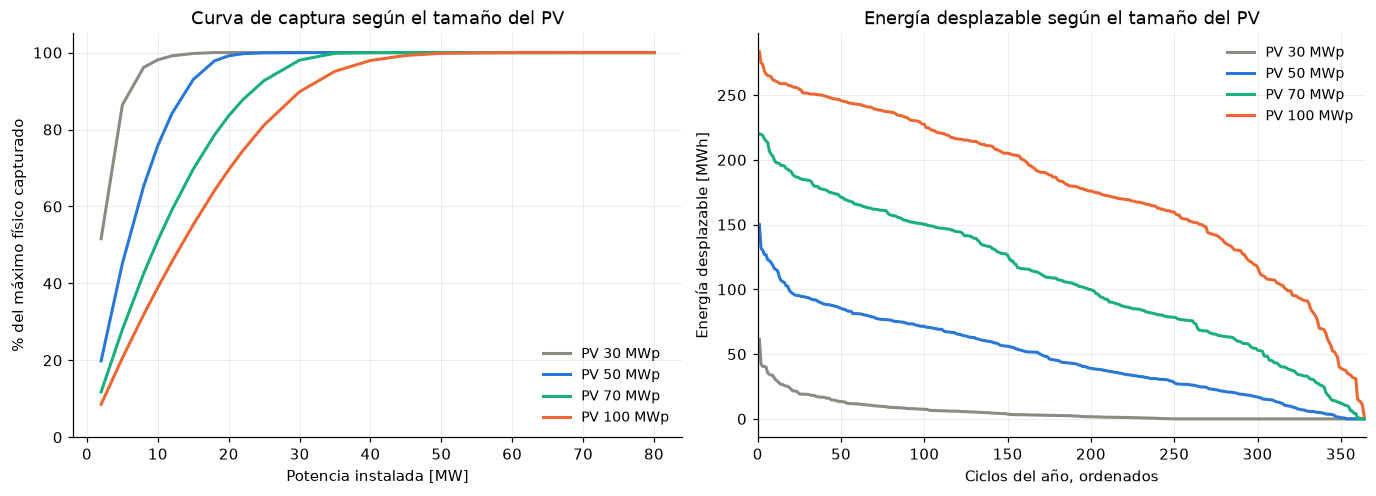

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.4, 4.4), constrained_layout=True)
colores = {30.0: GRIS, 50.0: AZUL, 70.0: AQUA, 100.0: NARANJA}

for pv, r in resultados.items():
    cur = r["_curva"]
    ax1.plot(cur["P [MW]"], cur["% del máximo físico"], lw=2,
             color=colores[pv], label=f"PV {pv:.0f} MWp")
    orden = np.sort(r["_ciclos"]["E_shift"].to_numpy())[::-1]
    ax2.plot(np.arange(1, len(orden) + 1), orden, lw=2, color=colores[pv],
             label=f"PV {pv:.0f} MWp")

ax1.set(xlabel="Potencia instalada [MW]", ylabel="% del máximo físico capturado",
        title="Curva de captura según el tamaño del PV", ylim=(0, 105))
ax1.legend(frameon=False, fontsize=9)
ax2.set(xlabel="Ciclos del año, ordenados", ylabel="Energía desplazable [MWh]",
        title="Energía desplazable según el tamaño del PV", xlim=(0, 365))
ax2.legend(frameon=False, fontsize=9)

fig.savefig(FIGURAS / "04_comparacion_tamanos_pv.png", dpi=200, bbox_inches="tight")
plt.show()

## 8A. Dominio físico

Qué rangos tienen **utilidad técnica**, sin ningún juicio económico.

La tabla siguiente resume, para cada tamaño de PV, el rango de potencia entre la
rodilla y el 98 % de captura, y el rango de energía **en capacidad nominal** —ya
traducido con RTE y DoD, no en excedente AC.

In [14]:
dominio = []
for pv, r in resultados.items():
    cur = r["_curva"]
    rod = rodilla_de(cur)
    e50, e90 = r["E desplazable P50 [MWh]"], r["E desplazable P90 [MWh]"]
    dominio.append({
        "PV [MWp]": pv,
        "Rodilla [MW]": rod,
        "Captura en la rodilla [%]": float(np.interp(rod, cur["P [MW]"],
                                                     cur["% del máximo físico"])),
        "P al 98 % [MW]": r["P 98 % [MW]"],
        "Nominal para P50 [MWh]": e50 * EFF_C / DoD,
        "Nominal para P90 [MWh]": e90 * EFF_C / DoD,
    })

dom = pd.DataFrame(dominio).set_index("PV [MWp]")
display(dom.round(1))

print("La energía está en CAPACIDAD NOMINAL de placa, ya traducida desde el")
print(f"excedente AC con eff_c = {EFF_C:.4f} y DoD = {DoD:.0%}.")

,Rodilla [MW],Captura en la rodilla [%],P al 98 % [MW],Nominal para P50 [MWh],Nominal para P90 [MWh]
PV [MWp],,,,,
30.0,10.0,98.1,9.9,3.0,20.0
50.0,18.0,97.9,18.2,51.9,106.8
70.0,25.0,92.7,30.0,126.7,211.0
100.0,30.0,89.8,40.2,217.5,296.6


La energía está en CAPACIDAD NOMINAL de placa, ya traducida desde el
excedente AC con eff_c = 0.9487 y DoD = 80%.


## 8B. Malla económica propuesta

Esto es **distinto** del dominio físico. Una malla para el cuaderno 02 tiene que
permitirle encontrar el máximo de VPN, y para eso debe cubrir **ambos lados de la
rodilla** — no empezar donde la física deja de dar rendimientos.

Tres criterios explícitos:

1. **Conservar tamaños pequeños.** Un BESS por debajo de la rodilla captura menos
   energía pero cuesta mucho menos. Que eso convenga o no es exactamente lo que
   el cuaderno 02 debe decidir, y no se puede decidir si la malla no lo incluye.
2. **Cubrir hasta bastante después de la rodilla**, para que el óptimo no quede
   pegado al borde superior. Es el defecto que documenta `INFORME` §7.1.
3. **Incluir explícitamente la región de 20 MW / 80 MWh**, que apareció como
   óptima en análisis anteriores. Tiene que ser confirmada o descartada por el
   nuevo experimento, no excluida antes de correrlo.

Y una advertencia de lectura sobre el caso pequeño: que **PV = 30 MWp** deje
solo 2,1 GWh/año desplazables significa que ahí hay **poco potencial para un
BESS cargado desde excedente solar**, no que el BESS carezca de valor. Con
carga desde la red en horas baratas, arbitraje o exportación, un BESS puede
tener sentido económico incluso sin excedente propio. Esa parte no la decide
esta caracterización.

### El límite superior no es una garantía

Los 60 MW y los 320 MWh son un **límite inicial**, no una demostración de que el
óptimo económico cae dentro. La física acota la captura de energía; el VPN
depende además de precios, tarifa y CAPEX, y puede empujar hacia configuraciones
que esta caracterización no acota. La regla de cierre es explícita:

> **Si la mejor configuración cae en el máximo de potencia, de energía o de PV
> evaluado, ampliar ese eje y repetir el barrido.**

Es el defecto de `INFORME` §7.1 convertido en procedimiento.

In [15]:
p_rodilla = dom["Rodilla [MW]"].max()
p_tope = dom["P al 98 % [MW]"].max()
e_tope_nominal = dom["Nominal para P90 [MWh]"].max()

POTENCIA_OPCIONES = [5.0, 10.0, 20.0, 30.0, 40.0, 60.0]
ENERGIA_OPCIONES = [20.0, 40.0, 80.0, 120.0, 180.0, 240.0, 320.0]

print("=" * 78)
print("REFERENCIAS FÍSICAS QUE ORIENTAN LA MALLA")
print("=" * 78)
print(f"  Rodilla más alta de los cuatro PV      : {p_rodilla:6.1f} MW")
print(f"  Potencia al 98 % más alta              : {p_tope:6.1f} MW")
print(f"  Techo de descarga hacia la demanda     : {df['Residual_MW'].max():6.1f} MW")
print(f"  Capacidad nominal para el P90 de energía: {e_tope_nominal:6.1f} MWh")
print()
print("=" * 78)
print("MALLA PROPUESTA  (solo propuesta: no se aplica a ningún cuaderno)")
print("=" * 78)
print(f"  POTENCIA_OPCIONES = {POTENCIA_OPCIONES}   # MW")
print(f"  ENERGIA_OPCIONES  = {ENERGIA_OPCIONES}   # MWh")
print("  BESS_MWh incluye 0: el cuaderno 02 debe poder concluir que no conviene batería.")
print()

# El producto cartesiano completo contiene celdas sin sentido fisico ni
# comercial: 5 MW / 320 MWh son 64 h de duracion, 60 MW / 20 MWh son 20 min.
# Se filtra por duracion nominal antes de gastar un MILP en cada una.
DUR_MIN, DUR_MAX = 1.0, 12.0
PARES = [(p, e) for p in POTENCIA_OPCIONES for e in ENERGIA_OPCIONES
         if DUR_MIN <= e / p <= DUR_MAX]

dur = pd.DataFrame(
    [[round(e / p, 1) if (p, e) in PARES else np.nan for e in ENERGIA_OPCIONES]
     for p in POTENCIA_OPCIONES],
    index=[f"{p:g} MW" for p in POTENCIA_OPCIONES],
    columns=[f"{e:g} MWh" for e in ENERGIA_OPCIONES],
)
print(f"  Duraciones nominales retenidas ({DUR_MIN:.0f}–{DUR_MAX:.0f} h; "
      f"'-' = descartada por duracion):")
print(dur.to_string(na_rep="-"))
print()
print(f"  Pares retenidos: {len(PARES)} de "
      f"{len(POTENCIA_OPCIONES) * len(ENERGIA_OPCIONES)}, mas el caso sin BESS.")
# El eje de PV NO sale de aqui: es el que ya tiene el cuaderno 02. Se cita
# para dimensionar el barrido, no para proponer cambiarlo.
PV_OPCIONES_NB02 = [0, 10, 20, 30, 40, 50, 70, 100, 150]
_con = len(PV_OPCIONES_NB02) * len(PARES)
_sin = len(PV_OPCIONES_NB02) - 1        # P=0 por cada PV, menos (PV=0, P=0)
print(f"  Con el eje de PV que ya tiene el 02 ({len(PV_OPCIONES_NB02)} puntos, sin cambiarlo):")
print(f"    configuraciones de diseno       : {_con + _sin}")
print(f"    evaluaciones estrategia x tarifa: {(_con + _sin) * 4 * 2}")
print(f"    llamadas reales a despachar()   : {(_sin + _con * 4) * 2}")
print(f"    llamadas a un solver MILP       : 0  (el 02 no usa PyPSA)")
print(f"  ¿Incluye 20 MW / 80 MWh (4 h)? "
      f"{'sí' if 20.0 in POTENCIA_OPCIONES and 80.0 in ENERGIA_OPCIONES else 'NO'}")
print(f"  ¿Cubre por debajo de la rodilla ({p_rodilla:.0f} MW)? "
      f"{'sí' if min(POTENCIA_OPCIONES) < p_rodilla else 'NO'}")
print(f"  ¿Cubre por encima del 98 % ({p_tope:.0f} MW)? "
      f"{'sí' if max(POTENCIA_OPCIONES) > p_tope else 'NO'}")
print()
print("  Los 60 MW son un LIMITE INICIAL, no una garantia de contener el optimo")
print("  economico: la fisica acota la captura, no el VPN. Regla de cierre:")
print("  si la mejor configuracion cae en el maximo de potencia, de energia o de")
print("  PV evaluado, ampliar ese eje y repetir el barrido.")

REFERENCIAS FÍSICAS QUE ORIENTAN LA MALLA
  Rodilla más alta de los cuatro PV      :   30.0 MW
  Potencia al 98 % más alta              :   40.2 MW
  Techo de descarga hacia la demanda     :   22.6 MW
  Capacidad nominal para el P90 de energía:  296.6 MWh

MALLA PROPUESTA  (solo propuesta: no se aplica a ningún cuaderno)
  POTENCIA_OPCIONES = [5.0, 10.0, 20.0, 30.0, 40.0, 60.0]   # MW
  ENERGIA_OPCIONES  = [20.0, 40.0, 80.0, 120.0, 180.0, 240.0, 320.0]   # MWh
  BESS_MWh incluye 0: el cuaderno 02 debe poder concluir que no conviene batería.

  Duraciones nominales retenidas (1–12 h; '-' = descartada por duracion):
       20 MWh  40 MWh  80 MWh  120 MWh  180 MWh  240 MWh  320 MWh
5 MW      4.0     8.0       -        -        -        -        -
10 MW     2.0     4.0     8.0     12.0        -        -        -
20 MW     1.0     2.0     4.0      6.0      9.0     12.0        -
30 MW       -     1.3     2.7      4.0      6.0      8.0     10.7
40 MW       -     1.0     2.0      3.0      4.5 

## 8C. Hasta dónde llega la curva de CAPEX

La malla anterior sale de la física. Falta comprobar que el **modelo de costo**
la soporte, porque una configuración que el CAPEX no sabe cotizar no produce un
VPN comparable: produce una extrapolación.

`costos.capex_bess()` delega en `costos_curvas.capex_bess_USD()`, que reconstruye
el modelo bottom-up de `CurvasCapexPVBESS.xlsx`. Dos cosas importan:

- La hoja `Curva_BESS` se titula **«duración 1 a 8 h»**. Ese es el dominio
  publicado.
- El costo depende de la duración por una **prima de C-rate**:
  `1 + pendiente · max(0, C − quiebre)`, calibrada sobre tres cotizaciones cuyos
  C-rate van de 0,25 a 0,60 —es decir, duraciones de **4,0 a 1,7 h**—.

Fuera de ese rango la función **no avisa ni recorta: extrapola en silencio**. No
lanza excepción, no emite advertencia y devuelve un número de aspecto normal.
Por eso conviene marcar el dominio antes de usar la malla, no después.

In [16]:
import costos_curvas as CC

DUR_CAPEX_MIN, DUR_CAPEX_MAX = 1.0, 8.0   # declarado en Curva_BESS!A1
_, _, _prima = CC._parametros(CC.LIBRO_CAPEX)


def segmento(e_MWh):
    """Segmento del libro. Se define por ENERGIA, no por duracion."""
    return "B1" if e_MWh < 1 else "B2" if e_MWh < 20 else "B3" if e_MWh <= 100 else "B4"


rejilla = pd.DataFrame([
    {
        "P [MW]": p,
        "E [MWh]": e,
        "Duración [h]": e / p,
        "C-rate": p / e,
        "Segmento": segmento(e),
        "CAPEX [USD/kWh]": CC.capex_bess_USD(p, e) / (e * 1_000),
        "Dominio CAPEX": "dentro" if DUR_CAPEX_MIN <= e / p <= DUR_CAPEX_MAX else "EXTRAPOLA",
    }
    for p, e in PARES
])
display(rejilla.round(2).set_index(["P [MW]", "E [MWh]"]))

dentro = rejilla[rejilla["Dominio CAPEX"] == "dentro"]
fuera = rejilla[rejilla["Dominio CAPEX"] == "EXTRAPOLA"]

print(f"Dominio publicado de la curva : {DUR_CAPEX_MIN:.0f} a {DUR_CAPEX_MAX:.0f} h")
print(f"Prima de C-rate               : quiebre {_prima['quiebre']:.2f} C, "
      f"pendiente {_prima['pendiente']:.2f}")
print(f"  activa solo por debajo de {1 / _prima['quiebre']:.0f} h; "
      f"por encima el factor es exactamente 1,00")
print()
print(f"Pares dentro del dominio      : {len(dentro)} de {len(PARES)}")
if len(fuera):
    print("Pares que extrapolarian       :")
    for _, f in fuera.iterrows():
        print(f"    {f['P [MW]']:.0f} MW / {f['E [MWh]']:.0f} MWh "
              f"= {f['Duración [h]']:.1f} h")
print()
print(f"Pares en el segmento B4 (>100 MWh): {(dentro['Segmento'] == 'B4').sum()} "
      f"de {len(dentro)}")
print("  B4 esta anclado en un sistema de 20 MW / 40 MWh, fuera de su propio")
print("  rango declarado, y su unica validacion cruzada -90 MW / 360 MWh- tiene")
print("  un error de +4,3 %, el mayor del libro. Es el segmento menos respaldado")
print("  y es donde cae buena parte de la malla: conviene declararlo.")

Duración [h]  C-rate Segmento  CAPEX [USD/kWh] Dominio CAPEX
P [MW] E [MWh]                                                              
5.0    20.0             4.00    0.25       B3           196.19        dentro
       40.0             8.00    0.12       B3           164.12        dentro
10.0   20.0             2.00    0.50       B3           225.15        dentro
       40.0             4.00    0.25       B3           178.60        dentro
       80.0             8.00    0.12       B3           155.33        dentro
       120.0           12.00    0.08       B4           164.75     EXTRAPOLA
20.0   20.0             1.00    1.00       B3           296.79        dentro
       40.0             2.00    0.50       B3           207.55        dentro
       80.0             4.00    0.25       B3           169.80        dentro
       120.0            6.00    0.17       B4           187.42        dentro
       180.0            9.00    0.11       B4           168.96     EXTRAPOLA
       240.0           12.00    0.08       B4           159.74     EXTRAPOLA
30.0   40.0             1.33    0.75       B3           243.37        dentro
       80.0             2.67    0.38       B3           184.28        dentro
       120.0            4.00    0.25       B4           210.08        dentro
       180.0            6.00    0.17       B4           184.07        dentro
       240.0            8.00    0.12       B4           171.07        dentro
       320.0           10.67    0.09       B4           161.32     EXTRAPOLA
40.0   40.0             1.00    1.00       B3           279.19        dentro
       80.0             2.00    0.50       B3           198.76        dentro
       120.0            3.00    0.33       B4           232.75        dentro
       180.0            4.50    0.22       B4           199.19        dentro
       240.0            6.00    0.17       B4           182.40        dentro
       320.0            8.00    0.12       B4           169.82        dentro
60.0   80.0             1.33    0.75       B3           234.58        dentro
       120.0            2.00    0.50       B4           278.08        dentro
       180.0            3.00    0.33       B4           229.41        dentro
       240.0            4.00    0.25       B4           205.07        dentro
       320.0            5.33    0.19       B4           186.82        dentro

Dominio publicado de la curva : 1 a 8 h
Prima de C-rate               : quiebre 0.50 C, pendiente 0.22
  activa solo por debajo de 2 h; por encima el factor es exactamente 1,00

Pares dentro del dominio      : 25 de 29
Pares que extrapolarian       :
    10 MW / 120 MWh = 12.0 h
    20 MW / 180 MWh = 9.0 h
    20 MW / 240 MWh = 12.0 h
    30 MW / 320 MWh = 10.7 h

Pares en el segmento B4 (>100 MWh): 12 de 25
  B4 esta anclado en un sistema de 20 MW / 40 MWh, fuera de su propio
  rango declarado, y su unica validacion cruzada -90 MW / 360 MWh- tiene
  un error de +4,3 %, el mayor del libro. Es el segmento menos respaldado
  y es donde cae buena parte de la malla: conviene declararlo.


**Decisión que queda abierta, y es tuya.** Hay dos mallas
posibles y el criterio no es técnico sino de alcance:

- **Malla estricta, 25 pares**: solo duraciones de 1 a 8 h. Todo VPN queda
  respaldado por la curva publicada.
- **Malla amplia, 29 pares**: añade cuatro celdas de 9 a 12 h. Explora si a la
  economía le conviene más energía por MW, a cambio de que esas cuatro
  cotizaciones sean una extensión del modelo y no un dato.

En cualquiera de las dos, las celdas de más de 100 MWh caen en el segmento B4 y
esa reserva debería viajar con el resultado.

### Qué queda declarado

**Lo que este cuaderno afirma.** Cuánta energía es físicamente desplazable dentro
de ciclos causales, qué potencia hace falta para capturar cada fracción de ella,
dónde está la rodilla de rendimientos decrecientes, y cómo se traduce el
excedente AC a capacidad nominal de placa.

**Lo que no afirma.**

- **Nada económico.** No hay CAPEX, VPN ni TIR. Una configuración físicamente
  útil puede ser económicamente absurda, y al revés: un BESS pequeño que captura
  el 40 % puede tener mejor VPN que uno grande que captura el 95 %.
- **Ninguna batería «captura el 100 %».** Las cifras de captura son de
  **conversión**, no de almacenamiento: suponen que la energía cabe. La
  restricción de capacidad, SOC y ciclado la impone el cuaderno 02 al simular.
- **La traducción AC → nominal es estática.** Aplica RTE y DoD a un balance
  energético, no a una trayectoria de SOC. Un despacho real puede necesitar más
  placa por no llegar nunca a vaciar la batería del todo.
- **Un solo sitio y un solo año.** Es Oriente en 2025. Las otras cuatro regiones
  tienen más recurso, así que su exigencia de potencia de carga será mayor.